# Mann-Kendall Trend Test — Simple xarray Utility

Give this notebook an `xarray.DataArray` time series (e.g. annual area
burnt, annual mean FWI, annual rainfall) and it will plot the series with
the Sen's slope trend line, and report the slope, p-value, and whether the
trend is statistically significant.

**Usage:** edit the `Input` cell to point at your own data, then run all cells.


In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pymannkendall as mk

plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True


## Input

Replace this cell with your own `xarray.DataArray`. It must:
- be 1-dimensional
- have a `time` coordinate (any dtype — datetime, or plain years as integers)

The example below builds a small synthetic series so the notebook runs
out of the box.


In [2]:
# --- Example synthetic input (replace with your own DataArray) ---
np.random.seed(1)
years = np.arange(1990, 2025)
values = 400 + 15 * (years - years[0]) + np.random.gamma(2.0, 150, len(years))

da = xr.DataArray(
    values,
    coords={"time": years},
    dims="time",
    name="area_burnt_ha",
    attrs={"units": "ha", "long_name": "Annual area burnt"}
)

da


<xarray.DataArray 'area_burnt_ha' (time: 35)> Size: 280B
array([1114.92130352,  564.26094292,  591.03419249,  539.46785742,
       1222.95830958,  604.66664896, 1143.47455827,  530.63795854,
       1060.09675157,  626.76899826,  768.07393438,  680.62398821,
        671.6967518 , 1138.64954421, 1078.17315224,  764.59538289,
        841.62916756, 1022.4086951 ,  809.14352384,  804.44695423,
        790.05050695, 1013.19737299,  944.6608688 ,  859.49612717,
       1019.96851521,  920.82222029, 1063.9980555 , 1194.57963532,
       1132.74923107, 1022.80302265, 1061.69041892, 1246.67415289,
       1189.48198887, 1358.56488147, 1273.06401626])
Coordinates:
  * time     (time) int64 280B 1990 1991 1992 1993 1994 ... 2021 2022 2023 2024
Attributes:
    units:      ha
    long_name:  Annual area burnt

## Trend function

One function: pass it any 1-D `xarray.DataArray` with a `time` coordinate,
it runs the Mann-Kendall test (via `pymannkendall`, which also returns
Sen's slope) and plots the result.


In [3]:
def plot_mk_trend(da, alpha=0.05, ax=None):
    """
    Run a Mann-Kendall trend test on a 1-D xarray.DataArray and plot the
    series with the Sen's slope trend line overlaid.

    Parameters
    ----------
    da : xarray.DataArray
        1-D series with a 'time' coordinate.
    alpha : float
        Significance level (default 0.05).
    ax : matplotlib.axes.Axes, optional
        Axis to plot on. A new figure/axis is created if not given.

    Returns
    -------
    result : pymannkendall MK_result namedtuple
        Contains .trend, .h, .p, .z, .s, .slope, .intercept, etc.
    """
    if da.ndim != 1:
        raise ValueError(f"Expected a 1-D DataArray, got {da.ndim} dimensions.")

    time_vals = da["time"].values
    y = da.values

    # x-axis as a plain numeric index (works for years, datetimes, etc.)
    if np.issubdtype(time_vals.dtype, np.datetime64):
        x_numeric = (time_vals - time_vals[0]) / np.timedelta64(1, "D") / 365.25
        x_plot = time_vals
    else:
        x_numeric = time_vals.astype(float) - time_vals[0]
        x_plot = time_vals

    result = mk.original_test(y, alpha=alpha)
    trend_line = result.intercept + result.slope * x_numeric

    if ax is None:
        fig, ax = plt.subplots()

    ax.plot(x_plot, y, marker="o", lw=1, color="#378ADD", label=da.name or "series")
    ax.plot(x_plot, trend_line, lw=2, color="#D85A30",
            label=f"Sen's slope = {result.slope:.3g} / step")

    sig_flag = "significant" if result.h else "not significant"
    units = da.attrs.get("units", "")
    ax.set_title(
        f"Mann-Kendall trend: {result.trend} ({sig_flag}, p={result.p:.4f})"
    )
    ax.set_xlabel("time")
    ax.set_ylabel(f"{da.attrs.get('long_name', da.name)} ({units})".strip())
    ax.legend()
    plt.tight_layout()

    print(f"Trend        : {result.trend}")
    print(f"Significant  : {result.h}  (alpha={alpha})")
    print(f"Sen's slope  : {result.slope:.4g} {units}/step")
    print(f"p-value      : {result.p:.4g}")
    print(f"Z statistic  : {result.z:.3f}")

    return result


## Run it

Trend        : increasing
Significant  : True  (alpha=0.05)
Sen's slope  : 18.11 ha/step
p-value      : 0.0001121
Z statistic  : 3.863


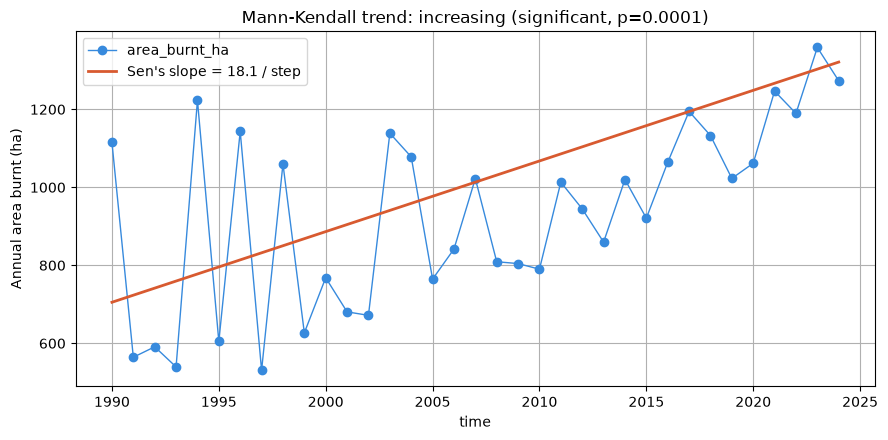

In [4]:
result = plot_mk_trend(da)
plt.show()


## Access individual results

`result` is a `pymannkendall` named tuple — pull out whichever field you need,
e.g. for writing a summary table across multiple stations/regions/grid cells.


In [5]:
print("slope     :", result.slope)
print("p-value   :", result.p)
print("significant:", result.h)
print("trend     :", result.trend)


slope     : 18.114282184731533
p-value   : 0.00011209958942570708
significant: True
trend     : increasing
